In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

In [2]:
# Load the dataset
df = pd.read_csv("online_shoppers_intention.csv")

In [3]:
# Preview the data
display(df.head())

# Check dataset dimensions
print("Rows and columns:", df.shape)

# Check column names
print(df.columns.tolist())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Rows and columns: (12330, 18)
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [4]:
df.info()

print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [5]:
print(df["Revenue"].value_counts())

print("\nPurchase outcome percentages:")
print(
    df["Revenue"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Revenue
False    10422
True      1908
Name: count, dtype: int64

Purchase outcome percentages:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


Explore shopper behavior (EDA)

In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


Compare purchasing and non-purchasing sessions

Revenue
False    28.714642
True     48.210168
Name: ProductRelated, dtype: float64


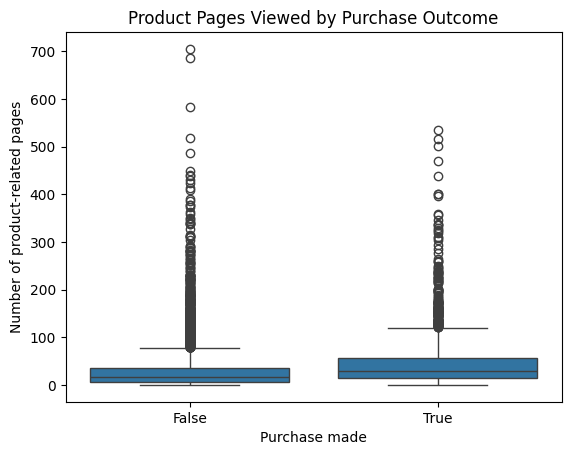

In [7]:
df["Revenue"] = df["Revenue"].astype(bool)

purchase_rate = (
    df.groupby("Revenue")["ProductRelated"]
      .mean()
)

print(purchase_rate)

sns.boxplot(
    data=df,
    x="Revenue",
    y="ProductRelated"
)

plt.title("Product Pages Viewed by Purchase Outcome")
plt.xlabel("Purchase made")
plt.ylabel("Number of product-related pages")
plt.show()

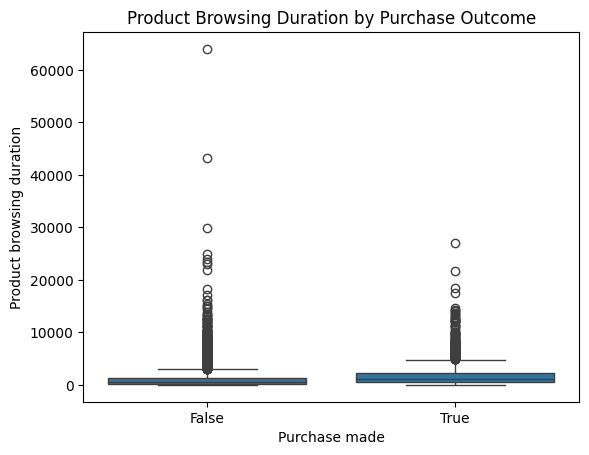

In [8]:
sns.boxplot(
    data=df,
    x="Revenue",
    y="ProductRelated_Duration"
)

plt.title("Product Browsing Duration by Purchase Outcome")
plt.xlabel("Purchase made")
plt.ylabel("Product browsing duration")
plt.show()

Examine the purchase rate

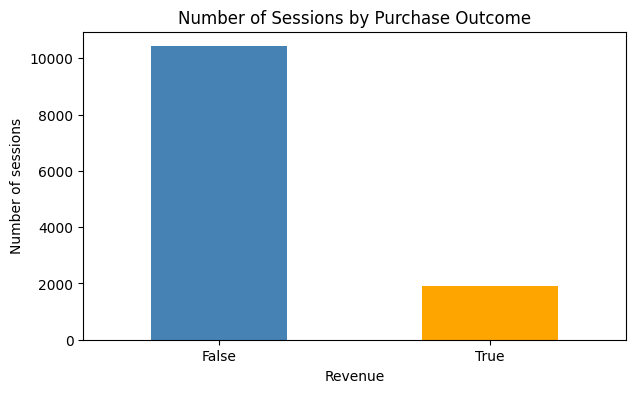

In [9]:
revenue_counts = df["Revenue"].value_counts()

revenue_counts.plot(
    kind="bar",
    figsize=(7, 4),
    color=["steelblue", "orange"]
)

plt.title("Number of Sessions by Purchase Outcome")
plt.xlabel("Revenue")
plt.ylabel("Number of sessions")
plt.xticks(rotation=0)
plt.show()

Explore relationships between behavioral variables

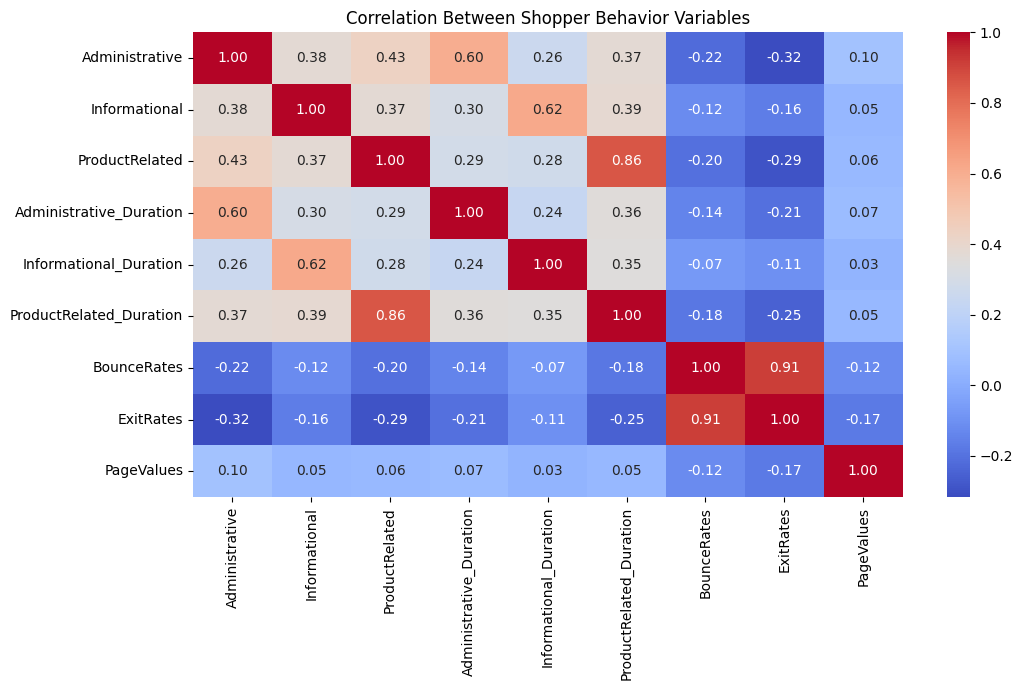

In [10]:
behavior_cols = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues"
]

plt.figure(figsize=(11, 7))

sns.heatmap(
    df[behavior_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Shopper Behavior Variables")
plt.tight_layout()
plt.show()

We can see some strong correlations

### Features Selection

In [11]:
features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates"
]

X = df[features].copy()

display(X.head())
print("Features used:", X.columns.tolist())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
0,0,0.0,0,0.0,1,0.000000,0.20,0.20
1,0,0.0,0,0.0,2,64.000000,0.00,0.10
2,0,0.0,0,0.0,1,0.000000,0.20,0.20
3,0,0.0,0,0.0,2,2.666667,0.05,0.14
4,0,0.0,0,0.0,10,627.500000,0.02,0.05


Features used: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']


In [12]:
print(X.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
dtype: int64


In [13]:
# Transform highly skewed variables
count_duration_cols = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration"
]

X[count_duration_cols] = np.log1p(X[count_duration_cols])

display(X.head())


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
0,0.0,0.0,0.0,0.0,0.693147,0.000000,0.20,0.20
1,0.0,0.0,0.0,0.0,1.098612,4.174387,0.00,0.10
2,0.0,0.0,0.0,0.0,0.693147,0.000000,0.20,0.20
3,0.0,0.0,0.0,0.0,1.098612,1.299283,0.05,0.14
4,0.0,0.0,0.0,0.0,2.397895,6.443336,0.02,0.05


### Scale the features

In [14]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Missing values after imputation:", np.isnan(X_scaled).sum())

Scaled data shape: (12330, 8)
Missing values after imputation: 0


Number of clusters

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(3000, len(X_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"k={k}: silhouette score={score:.4f}")

k=2: silhouette score=0.3225
k=3: silhouette score=0.4516
k=4: silhouette score=0.4294
k=5: silhouette score=0.3877
k=6: silhouette score=0.3856
k=7: silhouette score=0.3524
k=8: silhouette score=0.3442


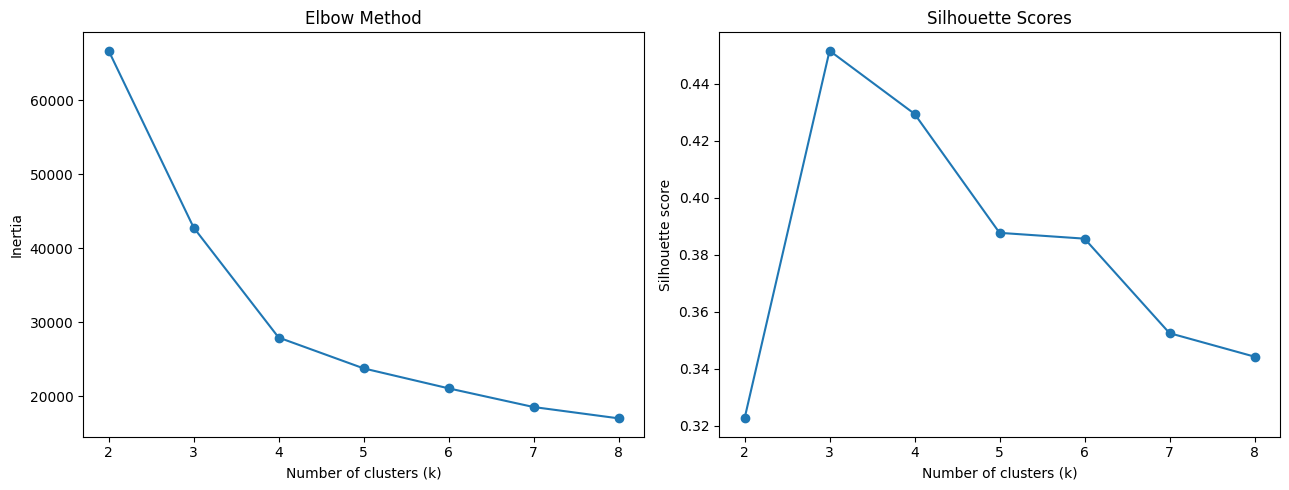

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    list(k_values),
    inertias,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

K= 2 and  K = 4 are the most promising options.
Let us compare both

In [17]:
#profile_data = df.copy()
valid_rows = X.notna().all(axis=1)
X = X.loc[valid_rows]
profile_data = df.loc[valid_rows].copy()

In [18]:


# Create K-Means models
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit models and assign cluster labels
profile_data['Cluster_K2'] = kmeans_2.fit_predict(X_scaled)
profile_data['Cluster_K4'] = kmeans_4.fit_predict(X_scaled)

print(profile_data[
    ['Cluster_K2', 'Cluster_K4']
].head())

   Cluster_K2  Cluster_K4
0           0           1
1           0           3
2           0           1
3           0           1
4           0           3


In [19]:
# K = 2
print("Cluster sizes for K = 2")
print(profile_data['Cluster_K2'].value_counts().sort_index())

# K = 4
print("\nCluster sizes for K = 4")
print(profile_data['Cluster_K4'].value_counts().sort_index())

Cluster sizes for K = 2
Cluster_K2
0    6130
1    6200
Name: count, dtype: int64

Cluster sizes for K = 4
Cluster_K4
0    4208
1     878
2    2214
3    5030
Name: count, dtype: int64


In [20]:
for k in [2, 4]:
    col = f'Cluster_K{k}'

    print(f"\nVisitor distribution for K = {k}")
    print(
        profile_data[col]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


Visitor distribution for K = 2
Cluster_K2
0    49.72
1    50.28
Name: proportion, dtype: float64

Visitor distribution for K = 4
Cluster_K4
0    34.13
1     7.12
2    17.96
3    40.79
Name: proportion, dtype: float64


Compare the actual customer profiles

In [21]:
behavior_features = [
    'Administrative',
    'Informational',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

# Average behavior for K = 2
profile_k2 = (
    profile_data.groupby('Cluster_K2')[behavior_features]
    .mean()
    .round(3)
)

print("CUSTOMER PROFILES: K = 2")
print(profile_k2)

# Average behavior for K = 4
profile_k4 = (
    profile_data.groupby('Cluster_K4')[behavior_features]
    .mean()
    .round(3)
)

print("\nCUSTOMER PROFILES: K = 4")
print(profile_k4)

CUSTOMER PROFILES: K = 2
            Administrative  Informational  ProductRelated  \
Cluster_K2                                                  
0                    0.163          0.045          14.832   
1                    4.443          0.957          48.440   

            ProductRelated_Duration  BounceRates  ExitRates  PageValues  \
Cluster_K2                                                                
0                           546.003        0.038      0.066       3.282   
1                          1836.165        0.006      0.021       8.467   

            SpecialDay  
Cluster_K2              
0                0.087  
1                0.036  

CUSTOMER PROFILES: K = 4
            Administrative  Informational  ProductRelated  \
Cluster_K4                                                  
0                    3.974          0.047          35.833   
1                    0.031          0.015           1.994   
2                    5.143          2.593          66.075  

Compare purchase rates across clusters

In [22]:
# Convert Revenue to numeric 0/1 if it is stored as True/False
revenue = profile_data['Revenue']

if revenue.dtype == 'object':
    revenue = revenue.astype(str).str.strip().str.lower().map({
        'true': 1,
        'false': 0
    })
else:
    revenue = revenue.astype(int)

profile_data['Revenue_numeric'] = revenue

for k in [2, 4]:
    col = f'Cluster_K{k}'

    purchase_summary = profile_data.groupby(col).agg(
        Visitors=('Revenue_numeric', 'size'),
        Purchases=('Revenue_numeric', 'sum'),
        Purchase_Rate=('Revenue_numeric', 'mean')
    )

    purchase_summary['Purchase_Rate'] *= 100

    print(f"\nPURCHASE BEHAVIOR: K = {k}")
    print(purchase_summary.round(2))


PURCHASE BEHAVIOR: K = 2
            Visitors  Purchases  Purchase_Rate
Cluster_K2                                    
0               6130        547           8.92
1               6200       1361          21.95

PURCHASE BEHAVIOR: K = 4
            Visitors  Purchases  Purchase_Rate
Cluster_K4                                    
0               4208        847          20.13
1                878          4           0.46
2               2214        528          23.85
3               5030        529          10.52


Visualize the cluster profiles

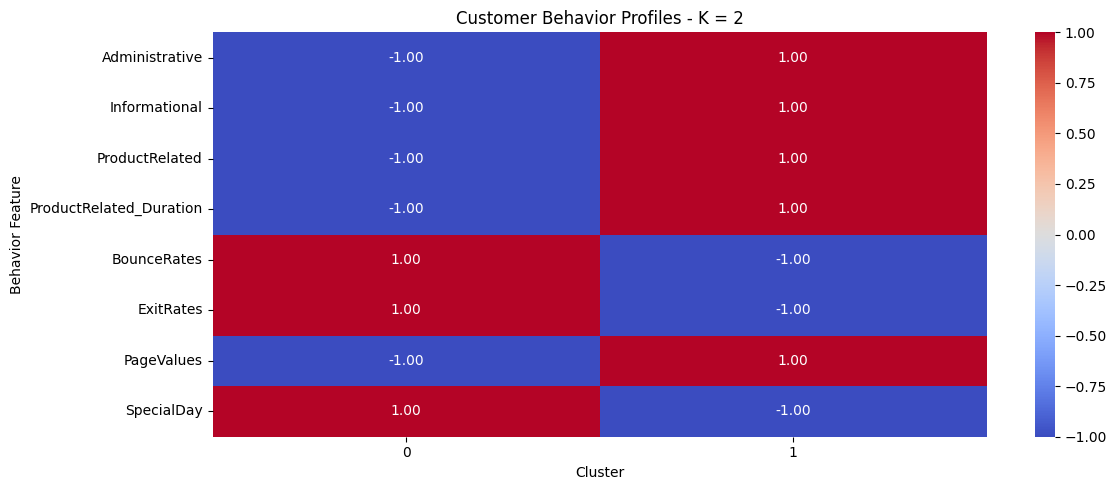

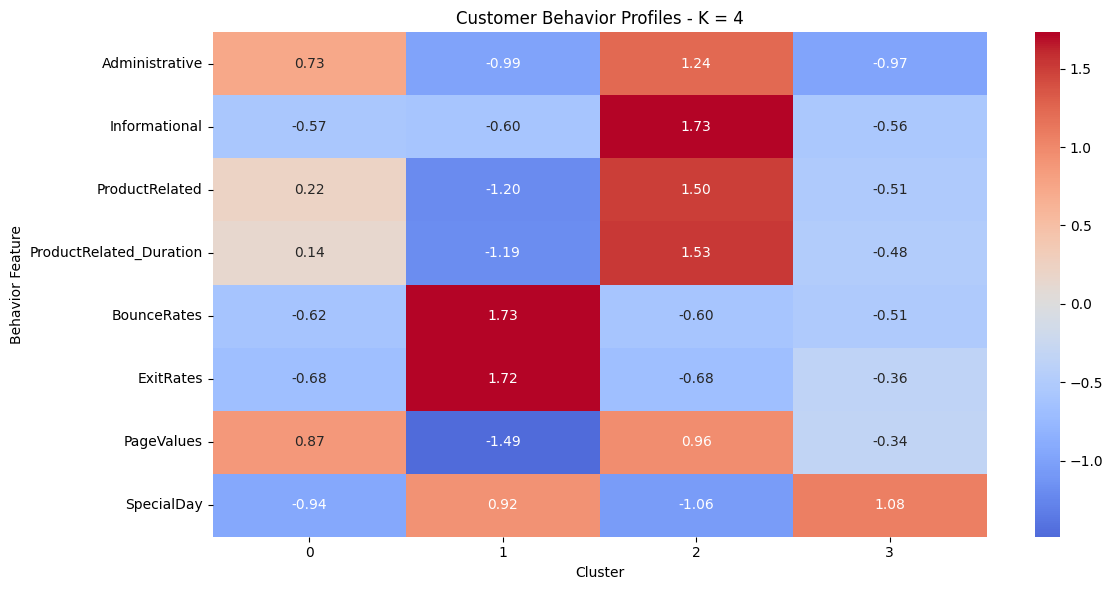

In [23]:
# Compare K = 2
profile_k2_scaled = (
    profile_k2 - profile_k2.mean()
) / profile_k2.std(ddof=0).replace(0, 1)

plt.figure(figsize=(12, 5))
sns.heatmap(
    profile_k2_scaled.T,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)
plt.title('Customer Behavior Profiles - K = 2')
plt.xlabel('Cluster')
plt.ylabel('Behavior Feature')
plt.tight_layout()
plt.show()


# Compare K = 4
profile_k4_scaled = (
    profile_k4 - profile_k4.mean()
) / profile_k4.std(ddof=0).replace(0, 1)

plt.figure(figsize=(12, 6))
sns.heatmap(
    profile_k4_scaled.T,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)
plt.title('Customer Behavior Profiles - K = 4')
plt.xlabel('Cluster')
plt.ylabel('Behavior Feature')
plt.tight_layout()
plt.show()

In [24]:
summaries = []

for k in [2, 4]:
    col = f'Cluster_K{k}'

    summary = profile_data.groupby(col).agg(
        Visitors=('Revenue_numeric', 'size'),
        Purchase_Rate=('Revenue_numeric', 'mean'),
        Avg_Product_Pages=('ProductRelated', 'mean'),
        Avg_Product_Duration=('ProductRelated_Duration', 'mean'),
        Avg_PageValues=('PageValues', 'mean'),
        Avg_Bounce_Rate=('BounceRates', 'mean'),
        Avg_Exit_Rate=('ExitRates', 'mean')
    ).reset_index()

    summary = summary.rename(columns={col: 'Cluster'})
    summary['K'] = k
    summary['Purchase_Rate'] *= 100
    summaries.append(summary)

comparison = pd.concat(summaries, ignore_index=True)

print(comparison.round(3).to_string(index=False))

 Cluster  Visitors  Purchase_Rate  Avg_Product_Pages  Avg_Product_Duration  Avg_PageValues  Avg_Bounce_Rate  Avg_Exit_Rate  K
       0      6130          8.923             14.832               546.003           3.282            0.038          0.066  2
       1      6200         21.952             48.440              1836.165           8.467            0.006          0.021  2
       0      4208         20.128             35.833              1287.908           8.108            0.006          0.022  4
       1       878          0.456              1.994                16.923           0.000            0.182          0.191  4
       2      2214         23.848             66.075              2623.678           8.427            0.007          0.022  4
       3      5030         10.517             18.374               693.444           3.944            0.014          0.044  4
